## 1. What Is Power-Line Interference?

Electrical power systems can introduce interference at frequencies of 50 Hz or 60 Hz into ECG recordings. In Bangladesh, the nominal power supply frequency is 50 Hz.

When this interference is present in an ECG recording, it may appear as additional oscillations or fine fluctuations superimposed on the signal.

A simplified model is:

\[
x(t)=s(t)+n_{50}(t)+n_{\text{other}}(t)
\]

Where:

- \(x(t)\) — Recorded ECG signal
- \(s(t)\) — Original cardiac signal
- \(n_{50}(t)\) — 50 Hz interference
- \(n_{\text{other}}(t)\) — Other noise

Our goal is to reduce the unwanted frequency component around 50 Hz without unnecessarily altering important features of the ECG signal.

**Important distinction:** Baseline wander generally consists of very low-frequency variations, whereas power-line interference occurs around a relatively specific frequency. Therefore, the same filtering technique is not always the most suitable choice for both problems.

## 2. Four Basic Types of Filters

### High-Pass Filter

Reduces low-frequency components while allowing relatively higher frequencies to pass. It can be useful for reducing baseline wander.

### Low-Pass Filter

Reduces high-frequency components. It can be used to suppress high-frequency noise in ECG signals.

### Bandpass Filter

Allows frequencies within a selected range, defined by lower and upper cutoff frequencies, to pass.

### Notch Filter

Reduces a narrow range of frequencies around a specific frequency, such as 50 Hz.

**Remember:** Filtering does not automatically improve a signal. Choosing inappropriate cutoff frequencies may also alter the original ECG waveform.

## 3. What Is a Butterworth Filter?

The Butterworth filter is a filter design characterized by a maximally flat frequency response in its passband. In SciPy, we can design this filter using `scipy.signal.butter()`.

Using `output="sos"` returns the filter in second-order sections (SOS) format, which is generally preferred for improved numerical stability.

Reference: [SciPy Signal Processing Manual](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.butter.html)

Three terms are important to understand:

- **Order:** Influences how quickly the filter response decreases beyond the cutoff frequency.
- **Cutoff frequency:** The frequency at which the Butterworth filter's magnitude response reaches approximately −3 dB relative to its passband level.
- **Sampling frequency:** The sampling rate of our dataset, \(f_s=360\) Hz.

### Nyquist Frequency

\[
f_{\mathrm{Nyquist}}=\frac{f_s}{2}=\frac{360}{2}=180\text{ Hz}
\]

Therefore, at a sampling rate of 360 Hz, the Nyquist frequency is 180 Hz. The cutoff frequencies of a digital filter must remain below this limit.

***50 Hz notch filter***

SciPy-এর iirnotch() দিয়ে একটি narrow-band notch filter তৈরি করা যায়। এটি একটি নির্দিষ্ট frequency-র আশেপাশের component কমানোর জন্য ডিজাইন করা হয়। 

প্রথমে আমরা notch filter-এর কাজ বুঝব, তারপর Butterworth bandpass filter প্রয়োগ করব।

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.datasets import electrocardiogram
from scipy.signal import iirnotch, filtfilt

# Load the ECG dataset
ecg = electrocardiogram()

# Sampling frequency
fs = 360

# Select 10 seconds of ECG
start_time = 5
end_time = 15

start_index = int(start_time * fs)
end_index = int(end_time * fs)

segment = ecg[start_index:end_index]

# Create the time axis
time = np.arange(start_index, end_index) / fs

print("Number of samples:", len(segment))
print("Duration:", len(segment) / fs, "seconds")

Number of samples: 3600
Duration: 10.0 seconds


কেন ১০ সেকেন্ডের segment?
\(10\times360=3600\) sample। এটি আমাদের filter চালানো এবং waveform তুলনা করার জন্য একটি সুবিধাজনক segment।
এখানে segment হলো raw ECG-এর একটি অংশ। আমরা original dataset পরিবর্তন করছি না।

***Notch filter তৈরি করো***

In [2]:
notch_frequency = 50
quality_factor = 30

b, a = iirnotch(
    w0=notch_frequency,
    Q=quality_factor,
    fs=fs
)

print("Numerator coefficients:", b)
print("Denominator coefficients:", a)

Numerator coefficients: [ 0.9856631  -1.26714406  0.9856631 ]
Denominator coefficients: [ 1.         -1.26714406  0.9713262 ]


### Understanding Each Parameter

- `notch_frequency = 50`: Specifies the frequency to be reduced, which is 50 Hz.
- `quality_factor = 30`: Controls how narrow the notch is. A higher Q factor generally produces a narrower notch bandwidth.
- `fs=fs`: Specifies the sampling frequency of the signal, which is 360 Hz.
- `b, a`: The numerator and denominator coefficients of the filter, which determine its mathematical behavior.

In SciPy's `iirnotch()`, we can specify the target frequency directly in Hz by providing the `w0` and `fs` parameters.

Reference: [SciPy `iirnotch()` Documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.iirnotch.html)

**Applying Filter**

In [5]:
notch_filtered = filtfilt(
    b,
    a,
    segment
)

Here:

b and a are the filter coefficients created in the previous step.

segment is the input ECG signal.

filtfilt() filters the signal in both forward and backward directions. This cancels phase shifts under ideal interior conditions, although edge effects may still occur.

The output of this filtering operation is stored in the notch_filtered variable. The original segment remains unchanged.

**Raw & filtered ECG compare**

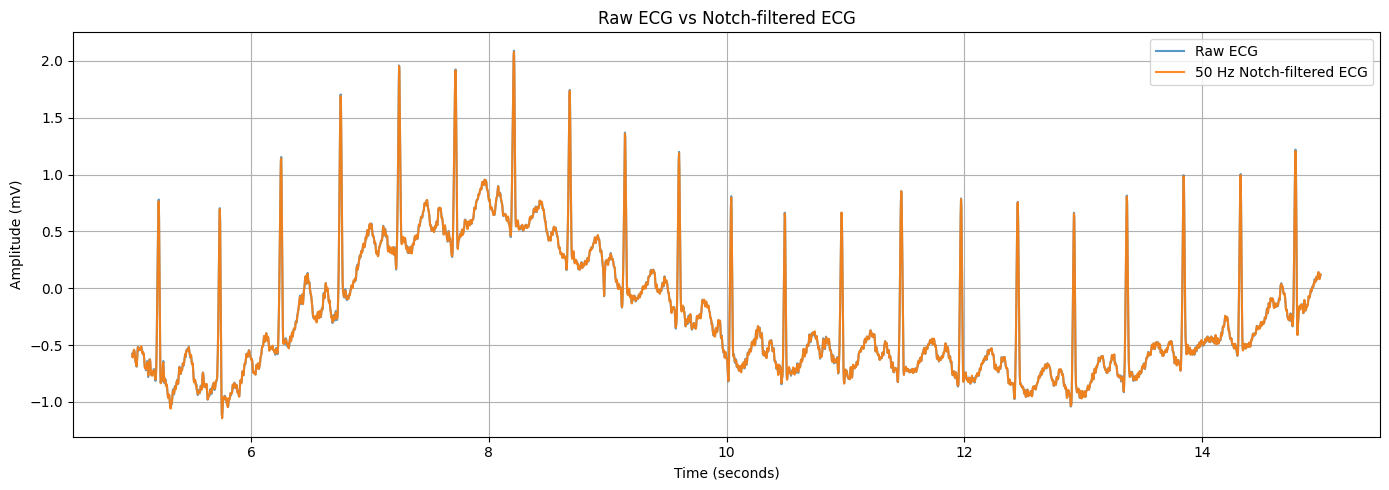

In [6]:
plt.figure(figsize=(14, 5))

plt.plot(
    time,
    segment,
    label="Raw ECG",
    alpha=0.75
)

plt.plot(
    time,
    notch_filtered,
    label="50 Hz Notch-filtered ECG",
    alpha=0.9
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("Raw ECG vs Notch-filtered ECG")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

***Butterworth bandpass filter***

A notch filter primarily targets a narrow frequency region, such as 50 Hz. In contrast, a bandpass filter reduces frequency components outside a specified frequency range.

In our demonstration, we will use a frequency range of 0.5–40 Hz. This is an example for learning purposes and may not be suitable for every ECG research task.

**Important:** Cutoff frequencies must be selected carefully, especially in clinical morphology analysis, because filtering can alter important ECG waveform features.

**Filter Design**

In [7]:
from scipy.signal import butter, sosfiltfilt

# Define the passband
low_cutoff = 0.5
high_cutoff = 40.0

# Design a Butterworth bandpass filter
sos = butter(
    N=4,
    Wn=[low_cutoff, high_cutoff],
    btype="bandpass",
    fs=fs,
    output="sos"
)

print("Filter coefficients shape:", sos.shape)

Filter coefficients shape: (4, 6)


### Understanding Each Parameter

**`from scipy.signal import butter, sosfiltfilt`**

- `butter()` designs the Butterworth filter.
- `sosfiltfilt()` applies the filter to the signal using a forward-backward filtering approach.

**`low_cutoff = 0.5`**

Sets the lower cutoff frequency to 0.5 Hz to reduce frequency components below this limit.

**`high_cutoff = 40.0`**

Sets the upper cutoff frequency to 40 Hz to reduce frequency components above this limit.

**`N=4`**

Sets the Butterworth filter design order to 4. Due to the bandpass transformation, the resulting filter has a higher effective order.

**`Wn=[low_cutoff, high_cutoff]`**

Defines the passband using the lower and upper cutoff frequencies.

**`btype="bandpass"`**

Specifies that we want to design a bandpass filter.

**`fs=fs`**

Specifies the sampling frequency so that the cutoff frequencies can be expressed directly in Hz.

**`output="sos"`**

Requests the filter coefficients in second-order sections (SOS) format. According to SciPy's documentation, this representation can provide better numerical stability and is generally recommended for typical filtering applications.

Reference: [SciPy Butterworth Filter Documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.butter.html)

***Apply Filter***

In [8]:
bandpass_filtered = sosfiltfilt(
    sos,
    segment
)

print("Original shape:", segment.shape)
print("Filtered shape:", bandpass_filtered.shape)

Original shape: (3600,)
Filtered shape: (3600,)


### Understanding the Filtering Output

Here:

- `sos` contains the coefficients of the Butterworth filter.
- `segment` is the input ECG signal.
- `bandpass_filtered` stores the filtered output signal.
- `shape` is checked to confirm that the input and output contain the same number of samples.

The `sosfiltfilt()` function uses forward-backward filtering and generally preserves the shape of the input array.

**Comparison and plotting between Raw ECG and Butterworth Bandpass-filtered ECG**

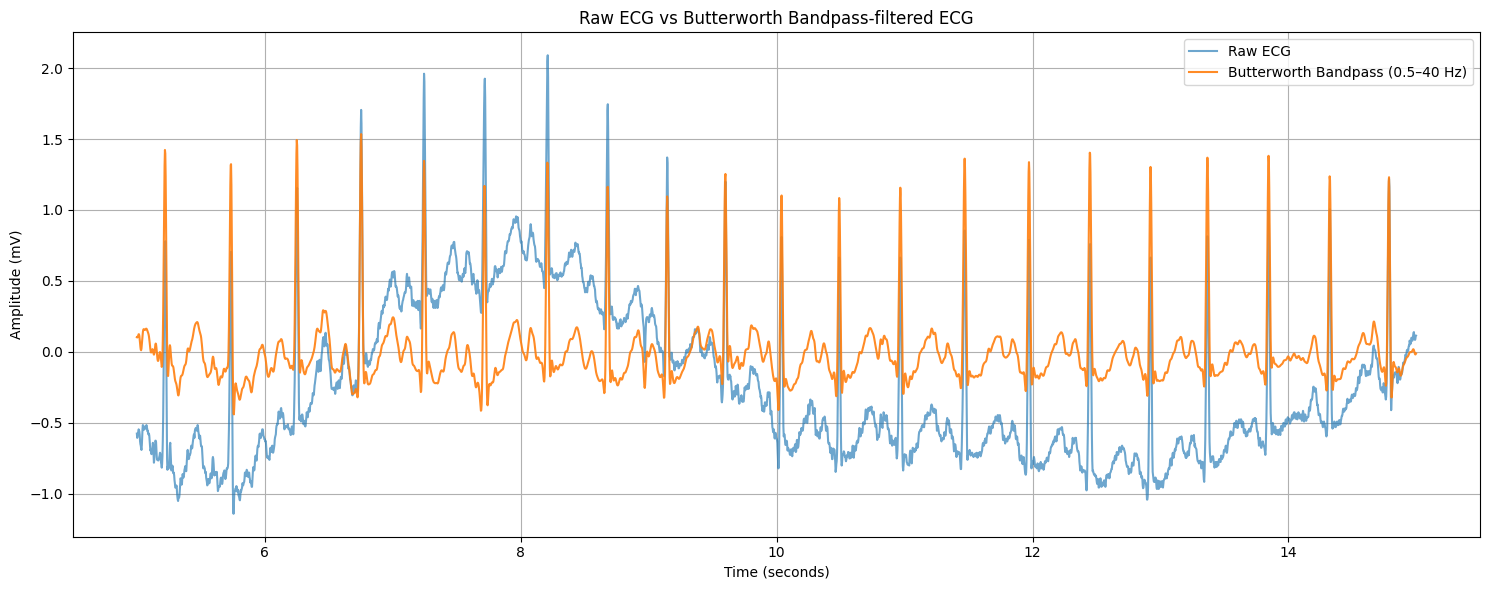

In [9]:
plt.figure(figsize=(15, 6))

plt.plot(
    time,
    segment,
    label="Raw ECG",
    alpha=0.65
)

plt.plot(
    time,
    bandpass_filtered,
    label="Butterworth Bandpass (0.5–40 Hz)",
    alpha=0.9
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("Raw ECG vs Butterworth Bandpass-filtered ECG")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Filter আসলে কোন frequency কমাচ্ছে?**

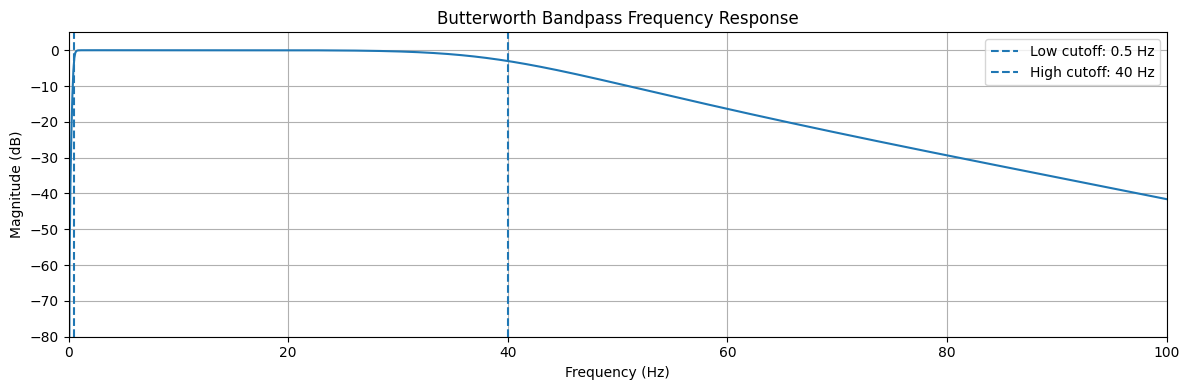

In [10]:
from scipy.signal import sosfreqz

# Calculate the frequency response
frequencies, response = sosfreqz(
    sos,
    worN=2048,
    fs=fs
)

# Convert magnitude to decibels
magnitude_db = 20 * np.log10(
    np.maximum(np.abs(response), 1e-10)
)

# Plot the frequency response
plt.figure(figsize=(12, 4))

plt.plot(frequencies, magnitude_db)

plt.axvline(
    low_cutoff,
    linestyle="--",
    label="Low cutoff: 0.5 Hz"
)

plt.axvline(
    high_cutoff,
    linestyle="--",
    label="High cutoff: 40 Hz"
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.title("Butterworth Bandpass Frequency Response")

plt.xlim(0, 100)
plt.ylim(-80, 5)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Explanation of the New Code

**`sosfreqz(sos, worN=2048, fs=fs)`**

Calculates the frequency response of the filter.

- `sos` — The Butterworth filter.
- `worN=2048` — Uses 2,048 frequency points to calculate the frequency response.
- `fs=fs` — Displays the frequency axis in Hz.

**`np.abs(response)`**

Calculates the magnitude of the complex-valued frequency response.

**`np.maximum(..., 1e-10)`**

Ensures that the magnitude does not become zero when calculating the logarithm.

**`20 * np.log10(...)`**

Converts the magnitude into decibels (dB). Larger negative dB values indicate greater attenuation at a particular frequency.

**`plt.axvline(...)`**

Marks the cutoff frequencies on the graph.

From the graph, you can observe that the filter response decreases outside the 0.5–40 Hz passband. However, frequencies immediately outside the cutoff points are not completely removed because the filter has a transition region.

## 7. Comparison of the Three Methods

| Method | Main Purpose | Key Consideration |
|---|---|---|
| Moving average | Estimates slow baseline variations. | Its performance depends on the window size. |
| 50 Hz notch filter | Reduces a narrow frequency band around 50 Hz. | Verify whether noise is actually present at that frequency. |
| Butterworth bandpass filter | Reduces frequency components outside a selected range. | Useful information outside the passband may also be lost. |

## 8. Research-Level Considerations

Keep the following practices in mind for your future ECG research:

1. **Never overwrite the raw signal.** Store the filtered signal in a separate variable.
2. **Specify the correct sampling frequency.** An incorrect `fs` value will lead to an incorrect interpretation of the filter's frequency settings.
3. **Inspect both waveform morphology and frequency response** after filtering.
4. **Do not assume that every segment contains a particular type of noise.** Check the signal characteristics before deciding which filtering method to apply.
5. **Document the filtering configuration clearly** in your research paper, including the filter type, order, cutoff frequencies, and filtering method.
6. **Understand the limitations of `sosfiltfilt()`.** Although it is useful for offline analysis, it is not suitable for conventional real-time processing of incoming samples because it requires forward-backward filtering rather than processing each sample using only past and current data.